
===== STUDENT PERFORMANCE DATA =====
 Name  Maths  Science  English
Rahul     85       90       80
Priya     92       89       94
Arjun     78       82       88
Sneha     95       96       91
Kiran     88       85       90

===== AVERAGE MARKS =====
 Name  Average
Rahul    85.00
Priya    91.67
Arjun    82.67
Sneha    94.00
Kiran    87.67

===== TOP-PERFORMING STUDENT =====
Name: Sneha
Average: 94.0


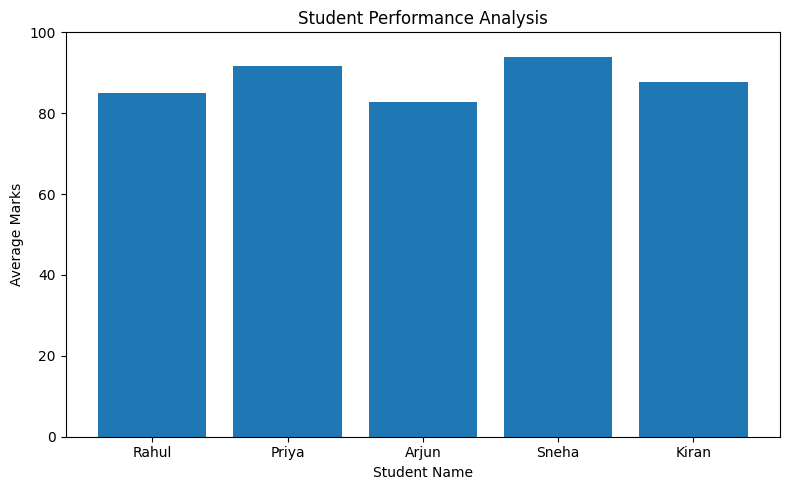


Analysis completed successfully!


NameError: name '__file__' is not defined

In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Get the folder containing this Python file
folder = os.getcwd()
csv_path = os.path.join(folder, "student_performance.csv")

# Create sample data if the CSV file is missing
if not os.path.exists(csv_path):
    data = {
        "Name": ["Rahul", "Priya", "Arjun", "Sneha", "Kiran"],
        "Maths": [85, 92, 78, 95, 88],
        "Science": [90, 89, 82, 96, 85],
        "English": [80, 94, 88, 91, 90]
    }

    df = pd.DataFrame(data)
    df.to_csv(csv_path, index=False)
    print("Sample CSV file created successfully!")

# Read student data
df = pd.read_csv(csv_path)

print("\n===== STUDENT PERFORMANCE DATA =====")
print(df.to_string(index=False))

# Calculate average marks
subjects = ["Maths", "Science", "English"]
df["Average"] = df[subjects].mean(axis=1)

print("\n===== AVERAGE MARKS =====")
print(df[["Name", "Average"]].round(2).to_string(index=False))

# Find the top-performing student
topper = df.loc[df["Average"].idxmax()]

print("\n===== TOP-PERFORMING STUDENT =====")
print("Name:", topper["Name"])
print("Average:", round(topper["Average"], 2))

# Display a bar chart
plt.figure(figsize=(8, 5))
plt.bar(df["Name"], df["Average"])
plt.title("Student Performance Analysis")
plt.xlabel("Student Name")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("\nAnalysis completed successfully!")
# Create cleaned CSV and save 3 visualizations

import os
import pandas as pd
import matplotlib.pyplot as plt

folder = os.path.dirname(os.path.abspath(__file__))
df = pd.read_csv(os.path.join(folder, "student_performance.csv"))

subjects = ["Maths", "Science", "English"]

# Clean data
df.columns = df.columns.str.strip()
df["Name"] = df["Name"].fillna("Unknown")

for col in subjects:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=subjects).copy()
df[subjects] = df[subjects].clip(0, 100)
df["Average"] = df[subjects].mean(axis=1).round(2)

# Save cleaned data
df.to_csv(
    os.path.join(folder, "cleaned_student_performance.csv"),
    index=False
)

# Visualization 1: Average marks
plt.figure(figsize=(8, 5))
plt.bar(df["Name"], df["Average"])
plt.title("Average Marks by Student")
plt.xlabel("Student")
plt.ylabel("Average Marks")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(os.path.join(folder, "visualization1_average_marks.png"))
plt.close()

# Visualization 2: Marks distribution
plt.figure(figsize=(8, 5))
for subject in subjects:
    plt.hist(df[subject], bins=10, alpha=0.5, label=subject)
plt.title("Marks Distribution")
plt.xlabel("Marks")
plt.ylabel("Number of Students")
plt.legend()
plt.tight_layout()
plt.savefig(os.path.join(folder, "visualization2_marks_distribution.png"))
plt.close()

# Visualization 3: Maths vs Science
plt.figure(figsize=(8, 5))
plt.scatter(df["Maths"], df["Science"])
plt.title("Maths vs Science")
plt.xlabel("Maths Marks")
plt.ylabel("Science Marks")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig(os.path.join(folder, "visualization3_maths_vs_science.png"))
plt.close()

print("Cleaned CSV and all 3 visualizations created successfully!")